# [County] County Prosecution Analysis

**Source:** [County] prosecution extract
**Study period:** 2017 to 2024 (filing year)

**Agreed criteria (all counties)**
- **Unit:** one row = one case = one docket number per defendant. Dockets with multiple defendants are split into one case per defendant.
- **Offense classification:** each case is classified by its most serious charge (felony over misdemeanor, then statutory class).
- **Outcome:** each case gets its most severe outcome across all charges (Trial Conviction > Plea > CWOF > Diversion > Acquittal > Dismissal > Other > Unknown). Open cases are excluded from outcome metrics.
- **Missing data:** the coverage table comes first. Fields over 20% missing are marked "insufficient data" and their metrics are not reported. "Unknown" is kept as its own category.

## Setup

In [1]:
import sys
!{sys.executable} -m pip install -U "openpyxl>=3.1"


[notice] A new release of pip is available: 25.1.1 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [2]:
import sys, subprocess, os
repo_root = subprocess.run(["git", "rev-parse", "--show-toplevel"],
                           capture_output=True, text=True).stdout.strip()
sys.path.insert(0, repo_root)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from viz_style import (set_style, stacked_pct_bar, save_fig, normalize_outcome,
                       case_outcome, OUTCOME_COLORS, TEXT_SECONDARY)

set_style()

COUNTY = "essex"        # e.g. "worcester"
YEARS = range(2017, 2024)     # 2017 to 2024
MISSING_THRESHOLD = 0.20      # fields above this are "insufficient data"
MIN_CELL = 30                 # suppress disparity cells smaller than this

FIG_DIR = os.path.join(repo_root, "figures", COUNTY)
os.makedirs(FIG_DIR, exist_ok=True)

## Load Data
Fill in the paths and map your extract's column names onto the shared names.
If your county has a single file, point both `FILED_PATH` and `DISPOSED_PATH` at it.

In [5]:
from pathlib import Path

FILED_PATH = "/Users/kan/Desktop/spark! prosecutor/essex/01 Criminal Charges Filed 2017-01-01_2025-12-31.csv"        # all filed charges (includes open cases)
DISPOSED_PATH = "/Users/kan/Desktop/spark! prosecutor/essex/02 Criminal Charges Disposed 2017-01-01_2025-12-31.csv"  # disposed charges

def read_any(path):
    """Read once from Excel, then reuse a fast pickle copy saved next to it."""
    cache = Path(path).with_suffix(".pkl")
    if cache.exists():
        return pd.read_pickle(cache)
    if path.endswith(".parquet"):
        df = pd.read_parquet(path)
    elif path.endswith((".xlsx", ".xls")):
        df = pd.read_excel(path, dtype=str)
    else:
        df = pd.read_csv(path, low_memory=False, dtype=str)
    df.columns = df.columns.str.strip()
    df.to_pickle(cache)
    return df

# Shared name : Essex column name. None = not in the Essex extract.
COLS = {
    "docket_number":    "Id Cs",
    "defendant_id":     "Id Prsn Mstr",
    "charge_count":     "Id Dfndnt Chrg",   # charge ID, not a count number; lowest per case = lead-charge proxy
    "filing_date":      "Date Evnt",        # event date (Code Evnt, e.g. ARR); Essex has no filing-date column
    "disposition_date": "Date Dspstn",
    "disposition":      "Desc Dspstn",      # e.g. "Dismissed Lack of Prosecution W/O Pred." -> add to OUTCOME_ALIASES
    "charge_level":     None,               # no felony/misdemeanor column
    "offense_category": None,               # no case type / crime type column
    "court":            "Desc Crt Lctn (ACTION EVENT)",
    "race":             "Code Rc",
    "sex":              "Code Sex",
    "sentence_type":    None,               # only jail-days columns ('D' = placeholder), no sentence type
}

def standardize(raw):
    rename = {v: k for k, v in COLS.items() if v is not None and v in raw.columns}
    out = raw.rename(columns=rename)
    for k in COLS:
        if k not in out.columns:
            out[k] = np.nan
    out["case_key"] = out["docket_number"].astype(str) + "_" + out["defendant_id"].astype(str)
    out["filing_date"] = pd.to_datetime(out["filing_date"], errors="coerce")
    out["disposition_date"] = pd.to_datetime(out["disposition_date"], errors="coerce")
    out["filing_year"] = out["filing_date"].dt.year
    return out

raw_filed = read_any(FILED_PATH)
raw_disposed = read_any(DISPOSED_PATH)
filed = standardize(raw_filed)
disposed = standardize(raw_disposed)

missing_cols = [k for k, v in COLS.items() if v is None or v not in raw_filed.columns]
print("Not found in extract:", missing_cols)
print(f"Filed: {len(filed):,} charges, {filed['case_key'].nunique():,} cases")
print(f"Disposed: {len(disposed):,} charges, {disposed['case_key'].nunique():,} cases")

Not found in extract: ['charge_level', 'offense_category', 'sentence_type']
Filed: 450,955 charges, 151,132 cases
Disposed: 436,315 charges, 149,007 cases


In [37]:
import re

# Essex has no offense-category column: derive it from the law chapter at the start of the charge code.
# Handles '94C . 32(a)', 'c. 90 s. 7C', '90. 10', '265/13A' ...
CHAPTER_CATEGORY = {
    "90": "Motor vehicle", "89": "Motor vehicle", "90B": "Motor vehicle", "90C": "Motor vehicle",
    "720C": "Motor vehicle", "540C": "Motor vehicle",
    "265": "Person",
    "266": "Property", "267": "Property",
    "94C": "Drug",
    "269": "Weapons", "140": "Weapons",
    "268": "Public order/justice", "272": "Public order/justice",
    "275": "Public order/justice", "276": "Public order/justice",
    "209A": "Protective order violation", "258E": "Protective order violation",
}
CHAPTER_RE = re.compile(r"^\s*(?:C\.?\s*)?(\d+[A-Z]?)")

def offense_from_code(code):
    if pd.isna(code) or str(code).strip() in ("", "666666", "999999"):
        return "Unknown"
    m = CHAPTER_RE.match(str(code).upper())
    return CHAPTER_CATEGORY.get(m.group(1), "Other") if m else "Unknown"

for df in (filed, disposed):
    df["offense_category"] = df["Code Chrg"].map(offense_from_code)
print(disposed["offense_category"].value_counts())

offense_category
Motor vehicle                 153703
Person                        112828
Property                       47210
Drug                           37938
Public order/justice           35662
Weapons                        28090
Protective order violation      9700
Other                           8614
Unknown                         2570
Name: count, dtype: int64


## Map Dispositions and Exclusions
Run the value counts, then map every disposition onto the shared buckets:
**Trial Conviction, Plea, CWOF, Diversion, Acquittal, Dismissal, Other, Unknown**, plus **Pending** for open charges.
Nolle prosequi counts as Dismissal. Unmapped values fall into Other, so check that the Other share is small.

In [6]:
disposed["disposition"].value_counts(dropna=False).head(40)

disposition
Dismissed                                  56828
Dismissed due to Indictment                52602
Dismissed Lack of Prosecution W/O Pred.    42247
Pled Guilty to Charge                      40389
Dismissed Court Costs                      36628
Continued Without Finding                  35427
Guilty                                     28835
Nolle Prosequi                             25572
Not Responsible                            24487
Responsible Filed                          20549
Guilty Probation                           16453
Generally Continuance                       9653
Dismissed Victim No Show                    6398
Guilty Filed                                5679
Pre-Trial Probation                         5199
Plea Lesser Offense                         4153
Responsible                                 3909
Guilty Fine                                 3283
Not Guilty                                  3204
Not Guilty by Jury                          2596
Admissio

In [7]:
COUNTY_OUTCOMES = {
    # "raw disposition value": "Shared bucket",
    # "dismissed": "Dismissal",
    # "nolle prosequi": "Dismissal",
    # "guilty": "Plea",
    # "jury trial guilty": "Trial Conviction",
    # "CWOF": "CWOF",
    # "pretrial probation": "Diversion",
    # "jury trial not guilty": "Acquittal",
    # "no disposition": "Pending",
}

# Non-criminal outcomes (e.g. civil infractions) and offense categories the client excluded
EXCLUDE_DISPOSITIONS = []   # raw disposition values for civil / non-criminal matters
EXCLUDE_OFFENSES = []       # e.g. ["Motor Vehicle"]

disposed["outcome"] = disposed["disposition"].replace(COUNTY_OUTCOMES).map(normalize_outcome)
disposed = disposed[~disposed["disposition"].isin(EXCLUDE_DISPOSITIONS)]
disposed = disposed[~disposed["offense_category"].isin(EXCLUDE_OFFENSES)]
filed = filed[~filed["offense_category"].isin(EXCLUDE_OFFENSES)]

print(disposed["outcome"].value_counts(dropna=False))
print(f"Share in Other: {(disposed['outcome'] == 'Other').mean():.1%}")

outcome
Other        350635
Dismissal     82400
Acquittal      3204
Diversion        41
Unknown          35
Name: count, dtype: int64
Share in Other: 80.4%


## 0. Data Coverage
Share missing and years available for each key field. Fields above 20% missing are marked **insufficient data** and the metrics that depend on them are not reported.

In [8]:
COVERAGE_FIELDS = ["docket_number", "defendant_id", "filing_date", "disposition_date",
                   "disposition", "charge_level", "offense_category", "court",
                   "race", "sex", "sentence_type"]

def years_available(d, field):
    yrs = d.loc[d[field].notna(), "filing_year"].dropna()
    return f"{int(yrs.min())}-{int(yrs.max())}" if len(yrs) else "none"

coverage = pd.DataFrame({
    "pct_missing": [disposed[f].isna().mean() * 100 for f in COVERAGE_FIELDS],
    "years_available": [years_available(disposed, f) for f in COVERAGE_FIELDS],
}, index=COVERAGE_FIELDS).round(1)
coverage["status"] = np.where(coverage["pct_missing"] > MISSING_THRESHOLD * 100,
                              "insufficient data", "ok")

INSUFFICIENT = set(coverage.index[coverage["status"] == "insufficient data"])
print("Insufficient:", INSUFFICIENT or "none")
coverage

Insufficient: {'sentence_type', 'offense_category', 'charge_level'}


,pct_missing,years_available,status
docket_number,0.0,1959-2048,ok
defendant_id,0.0,1959-2048,ok
filing_date,0.0,1959-2048,ok
disposition_date,0.0,1959-2048,ok
disposition,0.0,1959-2048,ok
charge_level,100.0,none,insufficient data
offense_category,100.0,none,insufficient data
court,0.1,1959-2048,ok
race,18.2,1959-2048,ok
sex,0.5,1959-2048,ok


**Notes:** [Describe any coverage gaps, e.g. a field only recorded after a certain year.]

## Build Case Table
One row per case (docket × defendant), restricted to filing years 2017 to 2024.
- **Most serious charge:** felony over misdemeanor, then lowest charge number as a tiebreak. Replace the tiebreak with statutory class if your extract has it.
- **Outcome:** most severe outcome across charges. Cases with any pending charge are marked Pending and excluded from outcome metrics.

In [9]:
LEVEL_RANK = {"Felony": 1, "Misdemeanor": 2}  # map your charge_level values here; others rank last

def build_cases(d, with_outcome):
    d = d[d["filing_year"].isin(YEARS)].copy()
    d["level_rank"] = d["charge_level"].map(LEVEL_RANK).fillna(9)
    d["charge_count_num"] = pd.to_numeric(d["charge_count"], errors="coerce").fillna(999)
    lead = (d.sort_values(["case_key", "level_rank", "charge_count_num"])
              .groupby("case_key").first())
    out = pd.DataFrame({
        "filing_year": lead["filing_year"],
        "filing_date": d.groupby("case_key")["filing_date"].min(),
        "charge_level": lead["charge_level"].fillna("Unknown"),
        "offense_category": lead["offense_category"].fillna("Unknown"),
        "court": lead["court"].fillna("Unknown"),
        "race": lead["race"].fillna("Unknown"),
        "sex": lead["sex"].fillna("Unknown"),
        "defendant_id": lead["defendant_id"],
        "n_charges": d.groupby("case_key").size(),
    })
    if with_outcome:
        out["outcome"] = d.groupby("case_key")["outcome"].agg(case_outcome)
        out["disposition_date"] = d.groupby("case_key")["disposition_date"].max()
    return out.reset_index()

filed_cases = build_cases(filed, with_outcome=False)
all_disposed_cases = build_cases(disposed, with_outcome=True)
n_pending = (all_disposed_cases["outcome"] == "Pending").sum()
cases = all_disposed_cases[all_disposed_cases["outcome"] != "Pending"].copy()

print(f"Filed cases 2017-2024: {len(filed_cases):,}")
print(f"Disposed cases 2017-2024: {len(cases):,} ({n_pending:,} pending excluded)")

Filed cases 2017-2024: 120,647
Disposed cases 2017-2024: 116,501 (0 pending excluded)


## 1. Volume and Trend
**Question:** How many cases were filed each year, and how has that changed since 2017?
**Metric:** case count per year, % change year over year and vs. 2017.

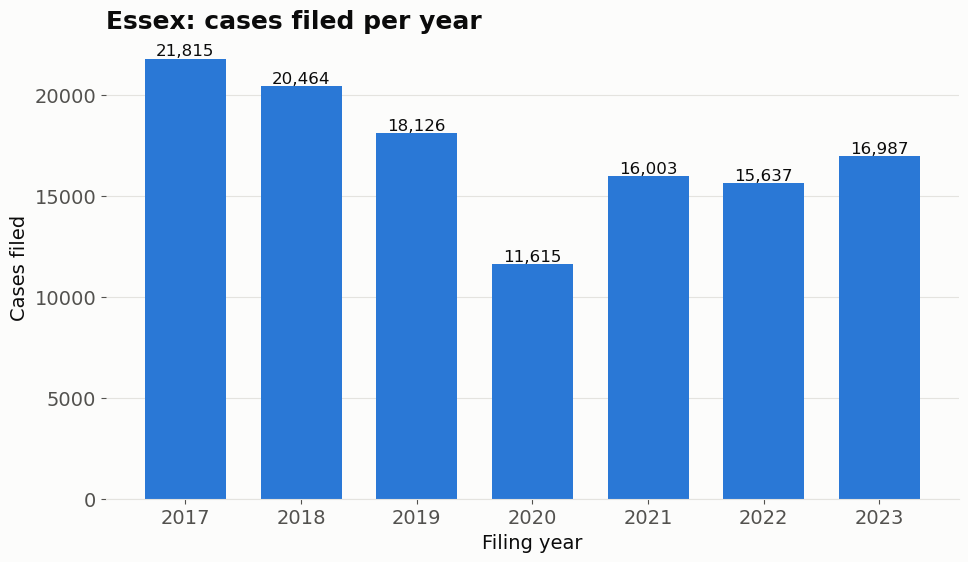

,cases,pct_change_yoy,pct_change_vs_2017
filing_year,,,
2017,21815,NaN,0.0
2018,20464,-6.2,-6.2
2019,18126,-11.4,-16.9
2020,11615,-35.9,-46.8
2021,16003,37.8,-26.6
2022,15637,-2.3,-28.3
2023,16987,8.6,-22.1


In [10]:
vol = filed_cases.groupby("filing_year").size().rename("cases").to_frame()
vol["pct_change_yoy"] = (vol["cases"].pct_change() * 100).round(1)
vol["pct_change_vs_2017"] = ((vol["cases"] / vol["cases"].iloc[0] - 1) * 100).round(1)

fig, ax = plt.subplots()
ax.bar(vol.index, vol["cases"], color=OUTCOME_COLORS["Trial Conviction"], width=0.7)
for x, n in zip(vol.index, vol["cases"]):
    ax.text(x, n, f"{n:,}", ha="center", va="bottom", fontsize=12)
ax.set_xticks(list(vol.index))
ax.set_ylabel("Cases filed")
ax.set_xlabel("Filing year")
ax.set_title(f"{COUNTY.title()}: cases filed per year")
save_fig(fig, f"{FIG_DIR}/q1_volume.png")
plt.show()
vol

**How this was calculated**
- **Unit:** cases (docket × defendant)
- **Source:** filed extract, so open cases are counted
- **Date field:** filing date (earliest charge in the case)
- **Filters:** filing years 2017 to 2024; [exclusions]

## 2. Per-Capita Rate
**Question:** How many cases are filed per 10,000 residents?
**Metric:** cases / annual county population × 10,000. Use annual ACS or PEP estimates, not a flat 2020 Census figure.

In [11]:
POPULATION = {  # annual county population estimates (Census PEP or ACS)
    2017: None, 2018: None, 2019: None, 2020: None,
    2021: None, 2022: None, 2023: None, 2024: None,
}

pop = pd.Series(POPULATION, dtype="float")
if pop.isna().any():
    print("Fill in POPULATION for:", list(pop.index[pop.isna()]))
else:
    per_cap = (vol["cases"] / pop * 10_000).round(1).rename("cases_per_10k").to_frame()
    fig, ax = plt.subplots()
    ax.plot(per_cap.index, per_cap["cases_per_10k"], marker="o", markersize=8,
            linewidth=2, color=OUTCOME_COLORS["Trial Conviction"])
    for x, v in zip(per_cap.index, per_cap["cases_per_10k"]):
        ax.annotate(f"{v:.0f}", (x, v), xytext=(0, 8), textcoords="offset points",
                    ha="center", fontsize=12)
    ax.set_xticks(list(per_cap.index))
    ax.set_ylabel("Cases per 10,000 residents")
    ax.set_xlabel("Filing year")
    ax.set_title(f"{COUNTY.title()}: cases filed per 10,000 residents")
    save_fig(fig, f"{FIG_DIR}/q2_per_capita.png")
    plt.show()
    display(per_cap)

Fill in POPULATION for: [2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024]


**How this was calculated**
- **Numerator:** cases filed per year (from Q1)
- **Denominator:** [population source and vintage]

## 3. Case Outcomes
**Question:** Of charged cases, what share end in dismissal, diversion, plea, trial conviction, or acquittal?
**Metric:** % of disposed criminal cases by most severe outcome, overall and by year. CWOF is reported separately.

,cases,pct
outcome,,
Other,85078,73.0
Dismissal,30011,25.8
Acquittal,1394,1.2
Diversion,11,0.0
Unknown,7,0.0


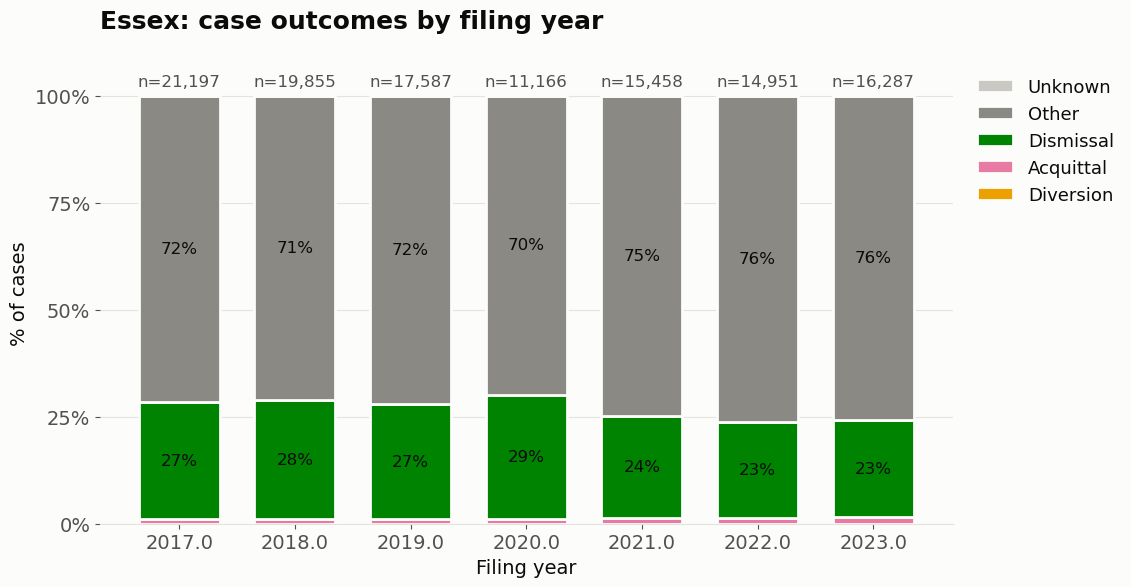

In [12]:
overall = cases["outcome"].value_counts().rename("cases").to_frame()
overall["pct"] = (overall["cases"] / overall["cases"].sum() * 100).round(1)
display(overall)

counts = cases.groupby("filing_year")["outcome"].value_counts().unstack(fill_value=0)
ax = stacked_pct_bar(counts, unit="cases",
                     title=f"{COUNTY.title()}: case outcomes by filing year",
                     xlabel="Filing year")
save_fig(ax.figure, f"{FIG_DIR}/q3_outcomes_by_year.png")
plt.show()

**How this was calculated**
- **Unit:** disposed criminal cases (docket × defendant), pending cases excluded
- **Outcome rule:** most severe outcome across the case's charges
- **Date field:** filing year
- **Mapping:** [list which raw dispositions went into each bucket]

**Note:** Cases filed in 2023 to 2024 that were still open at extraction are missing from the disposed extract, so recent years lean toward fast-resolving cases.

## 4. Sentencing
**Question:** What share of convictions result in incarceration, probation, or fines/other?
**Metric:** % of convicted cases (Trial Conviction or Plea) by most severe sentence type. The missing share is reported next to every rate.

In [13]:
SENTENCE_RANK = ["Incarceration", "Probation", "Fines/Other", "Unknown"]
SENTENCE_COLORS = {"Incarceration": "#2a78d6", "Probation": "#eb6834",
                   "Fines/Other": "#1baf7a", "Unknown": "#c9c8c2"}

def classify_sentence(text):
    """Parse free-text sentence type. Adjust keywords to your county's values."""
    if pd.isna(text) or str(text).strip() == "":
        return "Unknown"
    t = str(text).upper()
    if any(k in t for k in ["JAIL", "HOC", "HOUSE OF CORRECTION", "PRISON", "INCARC", "COMMITTED"]):
        return "Incarceration"
    if "PROBATION" in t:
        return "Probation"
    return "Fines/Other"

if "sentence_type" in INSUFFICIENT:
    print("Sentence type: insufficient data")
else:
    conv = disposed[disposed["outcome"].isin(["Trial Conviction", "Plea"])
                    & disposed["filing_year"].isin(YEARS)].copy()
    conv["sentence"] = conv["sentence_type"].map(classify_sentence)
    rank = {s: i for i, s in enumerate(SENTENCE_RANK)}
    case_sent = (conv.assign(r=conv["sentence"].map(rank))
                     .sort_values("r").groupby("case_key")
                     .agg(sentence=("sentence", "first"), filing_year=("filing_year", "first")))

    summary = case_sent["sentence"].value_counts().reindex(SENTENCE_RANK, fill_value=0).rename("cases").to_frame()
    summary["pct"] = (summary["cases"] / summary["cases"].sum() * 100).round(1)
    print(f"Missing sentence type: {summary.loc['Unknown', 'pct']}% of convicted cases")
    display(summary)

    by_year = case_sent.groupby("filing_year")["sentence"].value_counts().unstack(fill_value=0)
    by_year = by_year.reindex(columns=SENTENCE_RANK, fill_value=0)
    pct = by_year.div(by_year.sum(axis=1), axis=0) * 100
    fig, ax = plt.subplots()
    bottom = np.zeros(len(pct))
    for s in SENTENCE_RANK:
        ax.bar(pct.index, pct[s], bottom=bottom, color=SENTENCE_COLORS[s], label=s,
               width=0.7, edgecolor="#fcfcfb", linewidth=2)
        for x, v, b in zip(pct.index, pct[s], bottom):
            if v >= 6:
                ax.text(x, b + v / 2, f"{v:.0f}%", ha="center", va="center", fontsize=12)
        bottom += pct[s].values
    for x, n in zip(by_year.index, by_year.sum(axis=1)):
        ax.text(x, 101.5, f"n={n:,}", ha="center", va="bottom", fontsize=12, color=TEXT_SECONDARY)
    ax.set_ylim(0, 108); ax.set_xticks(list(pct.index))
    ax.set_ylabel("% of convicted cases"); ax.set_xlabel("Filing year")
    h, l = ax.get_legend_handles_labels()
    ax.legend(h[::-1], l[::-1], loc="upper left", bbox_to_anchor=(1.01, 1))
    ax.set_title(f"{COUNTY.title()}: sentence type for convicted cases", pad=24)
    save_fig(fig, f"{FIG_DIR}/q4_sentencing.png")
    plt.show()

Sentence type: insufficient data


**How this was calculated**
- **Unit:** convicted cases (Trial Conviction or Plea; CWOF is not a conviction)
- **Sentence rule:** most severe sentence across the case's convicted charges (Incarceration > Probation > Fines/Other)
- **Parsing:** [keywords used to classify sentence text]
- **Missing:** [share with no sentence type]

## 5. Pretrial Detention and Bail
**Question:** What share of defendants are held pretrial, and how often is cash bail set?
**Metric:** % released on personal recognizance, % with cash bail set, % held without bail, % of cash-bail cases unable to post, median bail amount.
Drop out-of-range bail dates before picking the first arraignment.

In [25]:
from pathlib import Path

def read_any(path):
    """Read once, then reuse a fast pickle copy saved next to the file."""
    cache = Path(path).with_suffix(".pkl")
    if cache.exists():
        return pd.read_pickle(cache)
    if path.endswith(".parquet"):
        df = pd.read_parquet(path)
    elif path.endswith((".xlsx", ".xls")):
        df = pd.read_excel(path, dtype=str)
    else:
        # Excel can save "CSV" with ; instead of , -> detect it from the header line
        for enc in ("utf-8-sig", "cp1252"):
            try:
                with open(path, encoding=enc) as f:
                    header = f.readline()
                sep = ";" if header.count(";") > header.count(",") else ","
                df = pd.read_csv(path, sep=sep, low_memory=False, dtype=str, encoding=enc)
                break
            except UnicodeDecodeError:
                continue
    df.columns = df.columns.str.strip()
    df.to_pickle(cache)
    return df
BAIL_PATH = "/Users/kan/Desktop/spark! prosecutor/essex/03 Bail and Pretrial Detention 2017-01-01_2025-12-31.csv"

# Essex bail file: one row per status event, ';'-separated, day.month.year dates, European amounts ("276,58").
# Columns: Id Cs, Id Prsn Mstr, Date Sts (status date), Desc Dfndnt Sts (status), Amnt Bl Set (bail set).

# Status events that are bail decisions. Everything else (Bail Warning, 60/90 Day Bail Warning,
# Warrant, Default, Deported, Deceased, ...) is a notice or event, not a release decision.
BAIL_DECISIONS = {
    "Bail Set at D/C Arraignment":      "BAILSET",
    "Bail Set at Juvenile Arraignment": "BAILSET",
    "Personal Recognizance":            "PR",
    "Out on Cash Bail":                 "CASHOUT",
    "In Custody":                       "CUSTODY",
    "GPS":                              "CONDITIONS",
    "House Arrest on Bracelet":         "CONDITIONS",
    "On Street":                        "RELEASED",
}

def euro_money(s):
    """'5.000,00' or '276,58' -> number"""
    return pd.to_numeric(s.astype(str).str.replace(".", "", regex=False)
                          .str.replace(",", ".", regex=False), errors="coerce")

def bail_status(kind, amount):
    if kind == "PR":
        return "PR"
    if kind in ("BAILSET", "CASHOUT", "CUSTODY") and amount > 0:
        return "Cash Bail"
    if kind == "CASHOUT":
        return "Cash Bail"
    if kind == "CUSTODY":
        return "Held Without Bail"      # in custody with no bail amount (approximation)
    return "Other"                      # GPS, house arrest, on street, bail set without an amount

if BAIL_PATH is None:
    print("No bail data for this county: insufficient data")
else:
    bail = read_any(BAIL_PATH).drop_duplicates()
    bail["case_key"] = bail["Id Cs"].astype(str).str.strip() + "_" + bail["Id Prsn Mstr"].astype(str).str.strip()
    bail["bail_date"] = pd.to_datetime(bail["Date Sts"], format="%d.%m.%Y", errors="coerce")
    bail["cash_amount"] = euro_money(bail["Amnt Bl Set"])
    bail["raw_status"] = bail["Desc Dfndnt Sts"].astype(str).str.strip()
    bail = bail[bail["bail_date"].dt.year.isin(YEARS)]                    # drop out-of-range dates
    bail = bail[bail["case_key"].isin(filed_cases["case_key"])]

    # First bail DECISION per case (skip warnings and other notices)
    dec = bail[bail["raw_status"].isin(BAIL_DECISIONS)].copy()
    dec["kind"] = dec["raw_status"].map(BAIL_DECISIONS)
    first = dec.sort_values("bail_date").drop_duplicates("case_key").set_index("case_key")
    first["status"] = [bail_status(k, a) for k, a in zip(first["kind"], first["cash_amount"])]

    # Cases with a bail record but no decision (mostly only "Bail Warning") -> Unknown
    all_keys = pd.Index(bail["case_key"].unique())
    status = first["status"].reindex(all_keys).fillna("Unknown")

    # Posted: later "Out on Cash Bail" = posted; "In Custody" with no "Out on Cash Bail" = not posted
    kinds = dec.groupby("case_key")["kind"].agg(set)
    cash_keys = status[status == "Cash Bail"].index
    posted = pd.Series(
        [True if "CASHOUT" in kinds.get(k, set()) else (False if "CUSTODY" in kinds.get(k, set()) else np.nan)
         for k in cash_keys], index=cash_keys)
    known_posted = posted.dropna()

    coverage_pct = len(all_keys) / len(filed_cases) * 100
    s = status.value_counts(normalize=True) * 100
    results = pd.Series({
        "bail record coverage (% of filed cases)": coverage_pct,
        "% PR": s.get("PR", 0),
        "% cash bail set": s.get("Cash Bail", 0),
        "% held without bail (in custody, no amount)": s.get("Held Without Bail", 0),
        "% other (GPS, house arrest, released)": s.get("Other", 0),
        "% no status (Unknown: warnings only)": s.get("Unknown", 0),
        "% of cash-bail cases unable to post": (known_posted == False).mean() * 100 if len(known_posted) else np.nan,
        "  cash-bail cases with posting info (n)": len(known_posted),
        "median cash bail ($)": first.loc[first["status"] == "Cash Bail", "cash_amount"].median(),
    }).round(1)
    display(results.to_frame("value"))

    known = status[status != "Unknown"]
    print(f"Among the {len(known):,} cases with a recorded bail decision:")
    print((known.value_counts(normalize=True) * 100).round(1).to_string())

,value
bail record coverage (% of filed cases),61.5
% PR,2.6
% cash bail set,21.2
"% held without bail (in custody, no amount)",9.6
"% other (GPS, house arrest, released)",5.6
% no status (Unknown: warnings only),61.0
% of cash-bail cases unable to post,85.5
cash-bail cases with posting info (n),945.0
median cash bail ($),1000.0


Among the 28,955 cases with a recorded bail decision:
status
Cash Bail            54.4
Held Without Bail    24.6
Other                14.3
PR                    6.7


**How this was calculated**
- **Unit:** cases with a bail record; first arraignment per case
- **Coverage:** [share of filed cases with any bail record]
- **Filters:** bail dates outside 2017 to 2024 dropped

## 6. Time to Disposition
**Question:** What is the median time from filing to disposition, and does it differ by case type?
**Metric:** median and IQR of days, by offense category and court. Pending cases and negative intervals are excluded.

In [39]:
# Make sure offense categories exist and cases are rebuilt with them
for df in (filed, disposed):
    df["offense_category"] = df["Code Chrg"].map(offense_from_code)
all_disposed_cases = build_cases(disposed, with_outcome=True)
cases = all_disposed_cases[all_disposed_cases["outcome"] != "Pending"].copy()
print(cases["offense_category"].value_counts())

offense_category
Motor vehicle                 51594
Person                        25427
Property                      14143
Drug                           8642
Public order/justice           7682
Protective order violation     3757
Other                          2678
Weapons                        1861
Unknown                         717
Name: count, dtype: int64


116,266 cases used; 235 negative intervals excluded
Overall median: 103 days (IQR 0-249)
Resolved on filing day: 26% of cases


,cases,median_days,q1,q3
offense_category,,,,
Weapons,1860,258.0,107.0,495.0
Drug,8633,199.0,89.0,392.0
Person,25402,182.0,105.0,314.0
Protective order violation,3754,175.0,87.0,306.0
Property,14114,155.0,58.0,308.0
Public order/justice,7670,104.0,28.0,245.0
Other,2670,35.0,0.0,162.0
Motor vehicle,51454,0.0,0.0,136.0
Unknown,709,0.0,0.0,60.0


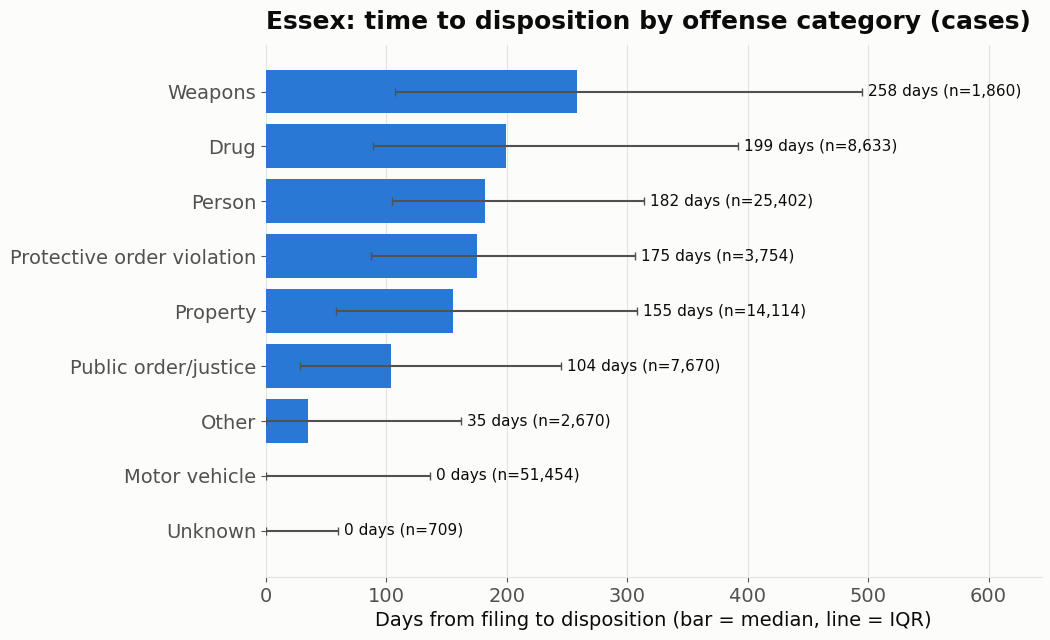

,cases,median_days,q1,q3
court,,,,
Lynn Juvenile Court,60,448.0,261.0,622.0
Lawrence Juvenile Court,140,428.0,233.0,672.0
Firearm Court - Lynn,429,375.0,165.0,627.0
Salem Juvenile Court,46,367.0,250.0,534.0
Salem Superior Court,533,353.0,157.0,652.0
Lynn District Court,25168,139.0,0.0,292.0
Lawrence District Court,32579,125.0,0.0,281.0
Salem District Court,15500,117.0,13.0,246.0
Gloucester District Court,4054,109.0,17.0,232.0


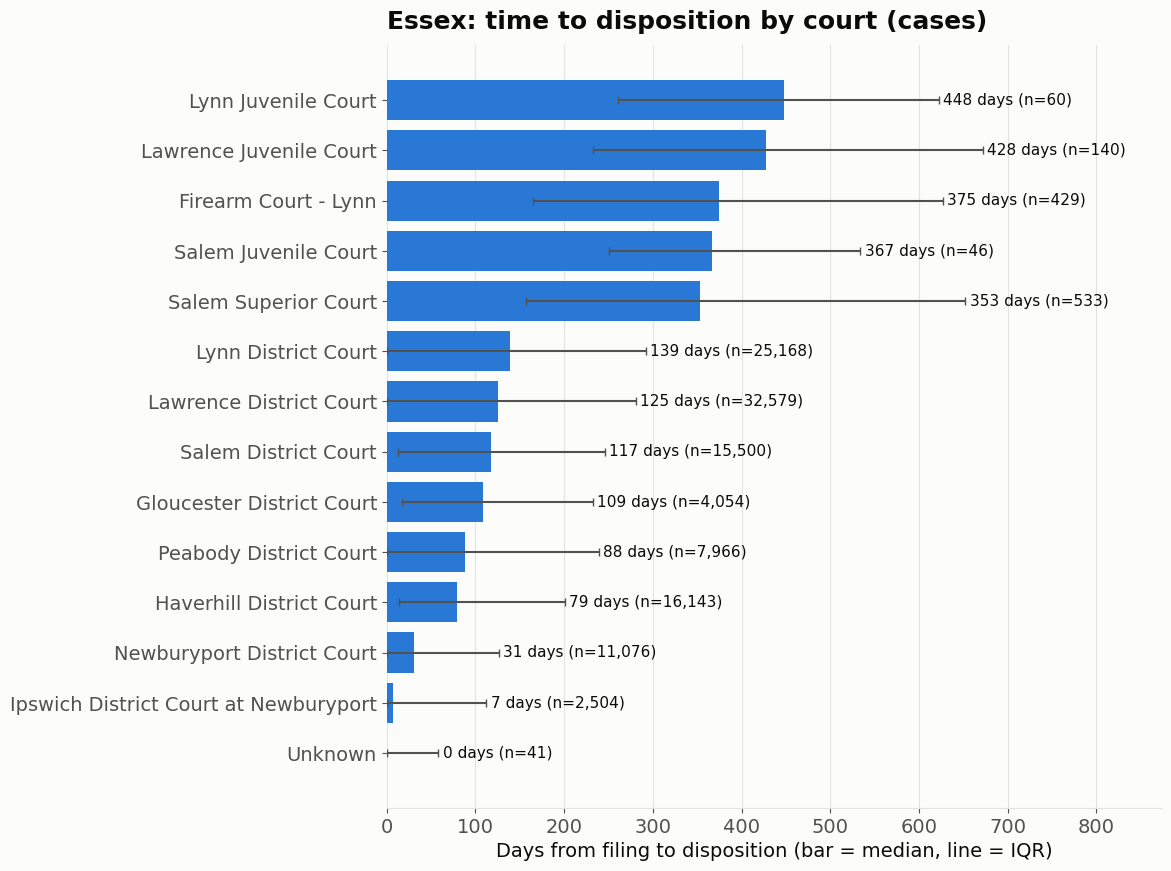

In [40]:
import re

# --- Offense category from the law chapter in the charge code (Essex has no category column) ---
CHAPTER_CATEGORY = {
    "90": "Motor vehicle", "89": "Motor vehicle", "90B": "Motor vehicle", "90C": "Motor vehicle",
    "720C": "Motor vehicle", "540C": "Motor vehicle",
    "265": "Person",
    "266": "Property", "267": "Property",
    "94C": "Drug",
    "269": "Weapons", "140": "Weapons",
    "268": "Public order/justice", "272": "Public order/justice",
    "275": "Public order/justice", "276": "Public order/justice",
    "209A": "Protective order violation", "258E": "Protective order violation",
}
CHAPTER_RE = re.compile(r"^\s*(?:C\.?\s*)?(\d+[A-Z]?)")

def offense_from_code(code):
    if pd.isna(code) or str(code).strip() in ("", "666666", "999999"):
        return "Unknown"
    m = CHAPTER_RE.match(str(code).upper())
    return CHAPTER_CATEGORY.get(m.group(1), "Other") if m else "Unknown"

for df in (filed, disposed):
    df["offense_category"] = df["Code Chrg"].map(offense_from_code)

# --- Rebuild cases so they carry the lead charge's offense category ---
all_disposed_cases = build_cases(disposed, with_outcome=True)
cases = all_disposed_cases[all_disposed_cases["outcome"] != "Pending"].copy()

# --- Time to disposition ---
t = cases.copy()
t["days"] = (t["disposition_date"] - t["filing_date"]).dt.days
n_negative = (t["days"] < 0).sum()
t = t[t["days"] >= 0]
print(f"{len(t):,} cases used; {n_negative:,} negative intervals excluded")
print(f"Overall median: {t['days'].median():.0f} days (IQR {t['days'].quantile(.25):.0f}-{t['days'].quantile(.75):.0f})")
print(f"Resolved on filing day: {(t['days'] == 0).mean():.0%} of cases")

def iqr_table(group):
    g = t.groupby(group)["days"]
    out = pd.DataFrame({"cases": g.size(), "median_days": g.median(),
                        "q1": g.quantile(0.25), "q3": g.quantile(0.75)})
    return out[out["cases"] >= MIN_CELL].sort_values("median_days", ascending=False).round(0)

def iqr_chart(table, title, path):
    top = table.head(15).iloc[::-1]
    fig, ax = plt.subplots(figsize=(10, max(4, 0.6 * len(top) + 1.5)))
    y = np.arange(len(top))
    ax.barh(y, top["median_days"], color=OUTCOME_COLORS["Trial Conviction"])
    ax.errorbar(top["median_days"], y,
                xerr=[top["median_days"] - top["q1"], top["q3"] - top["median_days"]],
                fmt="none", ecolor=TEXT_SECONDARY, capsize=3)
    ax.set_yticks(y)
    ax.set_yticklabels(top.index)
    for yi, (m, q3, n) in enumerate(zip(top["median_days"], top["q3"], top["cases"])):
        ax.text(q3 + 5, yi, f"{m:.0f} days (n={n:,})", va="center", fontsize=11)
    ax.set_xlim(0, top["q3"].max() * 1.3)
    ax.set_xlabel("Days from filing to disposition (bar = median, line = IQR)")
    ax.grid(axis="x"); ax.grid(axis="y", visible=False)
    ax.set_title(title, pad=12)
    save_fig(fig, path)
    plt.show()

by_offense = iqr_table("offense_category")
by_court = iqr_table("court")
display(by_offense)
iqr_chart(by_offense, f"{COUNTY.title()}: time to disposition by offense category (cases)",
          f"{FIG_DIR}/q6_time_by_offense.png")
display(by_court)
iqr_chart(by_court, f"{COUNTY.title()}: time to disposition by court (cases)",
          f"{FIG_DIR}/q6_time_by_court.png")

**How this was calculated**
- **Unit:** disposed cases
- **Interval:** earliest filing date to latest disposition date in the case
- **Filters:** pending cases and negative intervals excluded; categories with fewer than 30 cases hidden

## 7. Disparities by Race and Sex
**Question:** Do dismissal and incarceration rates differ by race/ethnicity and sex?
**Metric:** rate per group, plus rate ratios vs. White and vs. Male. Unknown race is kept as its own group. Groups under 30 cases are suppressed.

In [41]:
REF = {"race": "White", "sex": "Male"}  # adjust to your county's labels

def disparity(df, group, flag, label):
    g = df.groupby(group)[flag].agg(["size", "mean"]).rename(columns={"size": "cases", "mean": "rate"})
    g = g[g["cases"] >= MIN_CELL]
    ref = REF[group]
    g["rate_pct"] = (g["rate"] * 100).round(1)
    g["ratio_vs_" + ref] = (g["rate"] / g.loc[ref, "rate"]).round(2) if ref in g.index else np.nan
    return g.drop(columns="rate").assign(metric=label)

cases["dismissed"] = cases["outcome"] == "Dismissal"
results = []
for group in ["race", "sex"]:
    if group in INSUFFICIENT:
        print(f"{group}: insufficient data"); continue
    results.append(disparity(cases, group, "dismissed", "dismissal rate"))
    if "case_sent" in globals():
        inc = case_sent.join(cases.set_index("case_key")[[group]], how="inner")
        inc["incarcerated"] = inc["sentence"] == "Incarceration"
        results.append(disparity(inc, group, "incarcerated", "incarceration rate (convicted cases)"))
disp = pd.concat(results) if results else pd.DataFrame()
disp

,cases,rate_pct,ratio_vs_White,metric,ratio_vs_Male
0,261,28.7,NaN,dismissal rate,NaN
A,817,27.5,NaN,dismissal rate,NaN
B,9396,28.3,NaN,dismissal rate,NaN
H,23002,25.1,NaN,dismissal rate,NaN
M,180,37.2,NaN,dismissal rate,NaN
N,48,33.3,NaN,dismissal rate,NaN
P,65,23.1,NaN,dismissal rate,NaN
PI,42,33.3,NaN,dismissal rate,NaN
U,9129,27.3,NaN,dismissal rate,NaN
Unknown,21298,24.3,NaN,dismissal rate,NaN


,label,cases,rate_pct,ratio_vs_white
race,,,,
P,P,65,23.1,0.9
Unknown,Unknown,21298,24.3,0.9
H,Hispanic,23002,25.1,1.0
W,White,52263,25.8,1.0
U,Unknown (recorded),9129,27.3,1.1
A,Asian,817,27.5,1.1
B,Black,9396,28.3,1.1
0,0,261,28.7,1.1
N,N,48,33.3,1.3


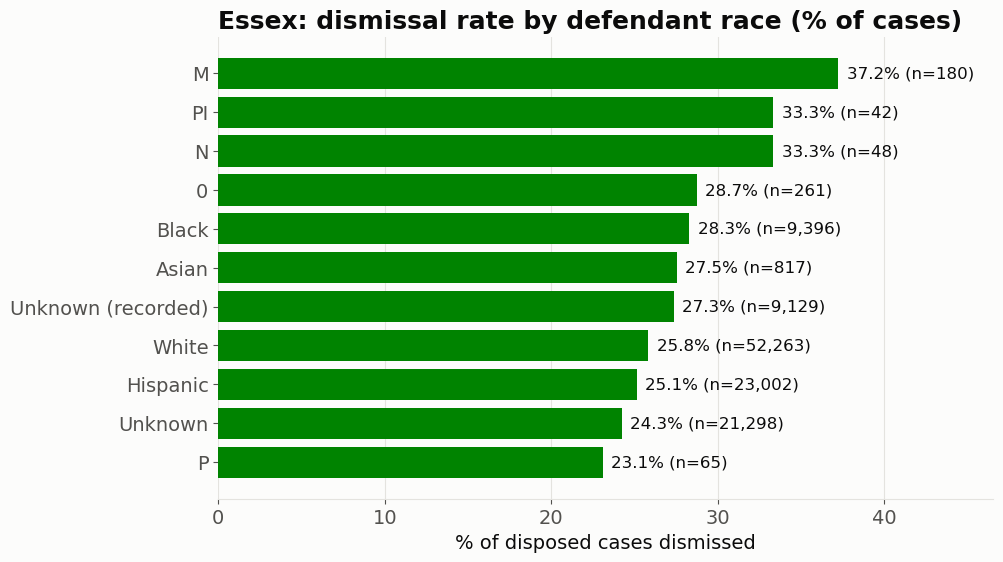

In [42]:
# Dismissal rate by race (chart): computed directly from cases so each race appears once
RACE_LABELS = {"W": "White", "B": "Black", "H": "Hispanic", "A": "Asian",
               "U": "Unknown (recorded)", "Missing": "Missing (blank)"}

if "race" not in INSUFFICIENT:
    g = cases.groupby(cases["race"].fillna("Missing").replace({"": "Missing"}))["outcome"]
    r = pd.DataFrame({
        "cases": g.size(),
        "rate_pct": g.apply(lambda s: (s == "Dismissal").mean() * 100),
    })
    white_rate = r.loc["W", "rate_pct"] if "W" in r.index else np.nan
    r["ratio_vs_white"] = (r["rate_pct"] / white_rate).round(2)
    r["label"] = [RACE_LABELS.get(k, k) for k in r.index]
    r = r.sort_values("rate_pct")
    display(r[["label", "cases", "rate_pct", "ratio_vs_white"]].round(1))

    fig, ax = plt.subplots(figsize=(10, 6))
    y = np.arange(len(r))
    ax.barh(y, r["rate_pct"], color=OUTCOME_COLORS["Dismissal"])
    ax.set_yticks(y)
    ax.set_yticklabels(r["label"])
    for yi, (v, n) in enumerate(zip(r["rate_pct"], r["cases"])):
        ax.text(v + 0.5, yi, f"{v:.1f}% (n={n:,})", va="center", fontsize=12)
    ax.set_xlim(0, r["rate_pct"].max() * 1.25)
    ax.set_xlabel("% of disposed cases dismissed")
    ax.grid(axis="x"); ax.grid(axis="y", visible=False)
    ax.set_title(f"{COUNTY.title()}: dismissal rate by defendant race (% of cases)")
    save_fig(fig, f"{FIG_DIR}/q7_dismissal_by_race.png")
    plt.show()

**How this was calculated**
- **Unit:** disposed cases (Id Cs × Id Prsn Mstr), pending cases excluded
- **Measure:** days from filing date to disposition date. Filing date = earliest `Date Evnt` in the case (Essex has no separate filing-date field); disposition date = latest `Date Dspstn` across the case's charges
- **Bars:** median days; **lines:** interquartile range (25th–75th percentile)
- **Offense category:** law chapter of the case's lead charge (charge code prefix): c.90/89 motor vehicle, c.265 person, c.266–267 property, c.94C drug, c.269/140 weapons, c.268/272/275/276 public order/justice, c.209A/258E protective order violations. Placeholder codes 666666/999999 → Unknown
- **Court:** `Desc Crt Lctn (ACTION EVENT)`
- **Excluded:** [235] cases with disposition before filing (negative intervals); groups with fewer than [MIN_CELL] cases
- **Overall:** median [103] days (IQR [0]–[249]); [X]% of cases were resolved on the filing date, which is why the 25th percentile is 0
- **Note:** cases filed in recent years that were still open at extraction are missing, so recent filing years lean toward fast-resolving cases

## 8. Disparities with Controls
**Question:** Do racial gaps remain within the same offense category and prior-record level?
**Metric:** dismissal rate by race within offense category × prior-record cells. Cells under 30 cases are suppressed.

**Prior record:** number of earlier cases for the same defendant filed in the **3 years** before this case (same lookback in every county), bucketed 0 / 1-2 / 3+.

In [43]:
LOOKBACK_YEARS = 3

if "defendant_id" in missing_cols:
    print("No defendant ID: prior record not measurable, insufficient data")
elif "race" in INSUFFICIENT:
    print("Race: insufficient data")
else:
    # Use all filed cases (any year) so cases early in the window still see prior history
    hist = (filed.groupby("case_key").agg(defendant_id=("defendant_id", "first"),
                                          filing_date=("filing_date", "min"))
                 .dropna().sort_values("filing_date"))

    def prior_count(g):
        dates = g["filing_date"].values
        start = dates - np.timedelta64(365 * LOOKBACK_YEARS, "D")
        return pd.Series(np.searchsorted(dates, dates, side="left")
                         - np.searchsorted(dates, start, side="left"), index=g.index)

    hist["prior_cases"] = hist.groupby("defendant_id", group_keys=False).apply(prior_count)
    hist["prior_record"] = pd.cut(hist["prior_cases"], [-1, 0, 2, np.inf], labels=["0", "1-2", "3+"])

    c = cases.merge(hist[["prior_record"]], left_on="case_key", right_index=True, how="left")
    cell = (c.groupby(["offense_category", "prior_record", "race"], observed=True)["dismissed"]
              .agg(cases="size", rate="mean").reset_index())
    cell = cell[cell["cases"] >= MIN_CELL]
    cell["rate_pct"] = (cell["rate"] * 100).round(1)

    wide = cell.pivot_table(index=["offense_category", "prior_record"], columns="race",
                            values="rate_pct", observed=True)
    if REF["race"] in wide.columns:
        for col in wide.columns:
            if col != REF["race"]:
                wide[f"{col} ratio"] = (wide[col] / wide[REF["race"]]).round(2)
    display(wide)

/var/folders/5k/8xhyhd0j7jx98f4ydy5f5tmm0000gn/T/ipykernel_58149/2541655503.py:19: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  hist["prior_cases"] = hist.groupby("defendant_id", group_keys=False).apply(prior_count)


race                                        0     A     B     H     M     U  \
offense_category           prior_record                                       
Drug                       0              NaN  42.9  36.6  37.4   NaN  42.4   
                           1-2            NaN   NaN  36.4  37.7   NaN  36.2   
                           3+             NaN   NaN  26.2  30.1   NaN  28.6   
Motor vehicle              0             23.2  28.7  29.4  22.5  35.7  25.0   
                           1-2            NaN  22.0  25.5  23.3   NaN  29.3   
                           3+             NaN   NaN  26.2  27.8   NaN  29.1   
Other                      0              NaN   NaN  63.8  76.4   NaN  83.2   
                           1-2            NaN   NaN  53.8  50.0   NaN   NaN   
                           3+             NaN   NaN   NaN  44.8   NaN   NaN   
Person                     0             23.5  17.3  18.1  16.8   NaN  16.2   
                           1-2            NaN   8.8  19.4  17.3   NaN  16.7   
                           3+             NaN   NaN  20.6  18.7   NaN  20.3   
Property                   0              NaN  30.2  27.9  24.2   NaN  29.8   
                           1-2            NaN   NaN  28.3  23.4   NaN  21.4   
                           3+             NaN   NaN  28.6  23.2   NaN  32.8   
Protective order violation 0              NaN   NaN  18.2  13.5   NaN  11.3   
                           1-2            NaN   NaN  12.1  18.6   NaN  13.3   
                           3+             NaN   NaN  16.7  15.7   NaN   NaN   
Public order/justice       0              NaN  25.0  41.2  35.2   NaN  40.4   
                           1-2            NaN   NaN  36.0  36.4   NaN  38.8   
                           3+             NaN   NaN  48.2  47.4   NaN   NaN   
Unknown                    0              NaN   NaN   NaN  47.4   NaN  44.9   
                           1-2            NaN   NaN   NaN   NaN   NaN   NaN   
                           3+             NaN   NaN   NaN   NaN   NaN   NaN   
Weapons                    0              NaN   NaN  68.5  49.2   NaN  55.7   
                           1-2            NaN   NaN  33.8  51.6   NaN  40.0   
                           3+             NaN   NaN   NaN  54.5   NaN   NaN   

race                                     Unknown     W  
offense_category           prior_record                 
Drug                       0                38.5  30.7  
                           1-2              33.1  29.3  
                           3+               15.6  29.8  
Motor vehicle              0                22.6  23.5  
                           1-2              24.5  23.2  
                           3+               25.8  25.9  
Other                      0                62.2  59.7  
                           1-2              57.4  48.1  
                           3+                NaN  36.4  
Person                     0                16.4  17.7  
                           1-2              17.2  18.6  
                           3+               19.2  20.1  
Property                   0                28.7  28.4  
                           1-2              22.7  25.0  
                           3+               19.6  22.8  
Protective order violation 0                12.3  12.1  
                           1-2              15.6  18.9  
                           3+               19.6  20.7  
Public order/justice       0                35.9  42.0  
                           1-2              39.2  43.9  
                           3+               37.3  47.6  
Unknown                    0                43.4  47.3  
                           1-2               NaN  53.6  
                           3+                NaN  72.7  
Weapons                    0                55.2  46.0  
                           1-2              41.2  44.3  
                           3+                NaN  37.6

**How this was calculated**
- **Unit:** disposed cases
- **Prior record:** earlier cases for the same defendant ID within 3 years before filing
- **Cells:** offense category × prior record × race; cells under 30 cases suppressed
- **Ratio:** group dismissal rate / White dismissal rate within the same cell

**Limitation:** Prior record only counts cases in this county's extract, not statewide history.

## Questions for the Client
- [e.g., Is a statewide prior-record field available?]
- [e.g., Can declined referrals be provided?]